# 133 · error classes on the augmentation ablation (nb132's binary scoring)
Every run is transformer4 `--decoder res --latent-norm rescale`, ep300 (eager eval, compile 0). p = fraction of training samples augmented, as `sg / jit / ld / bd`: speaker gain / laser-grid shift / laser-token dropout / band-token dropout. The iou08 scores are in runs/aug_ablation_scores.md.

| run | sg / jit / ld / bd | what |
|---|---|---|
| decres-rescale-v1 | 1 / 1 / 1 / 1 | reference |
| decres-rescale-aug10-v1 | .1 / .1 / .1 / .1 | all at 10% |
| decres-rescale-{sg10,jit10-v2,ld10,bd10} | one at .1, rest 1 | one aug reduced |
| decres-rescale-sgjit10-v1 / drop10-v1 | sg+jit / ld+bd at .1, rest 1 | two reduced |
| decres-rescale-noaug-v1 | 0 / 0 / 0 / 0 | no augmentation |
| decres-rescale-only-{sg10,jit10,drop10,sgjit10,sgdrop10,jitdrop10}-v1 | listed at .1, rest 0 | isolation queue (tmux train:augiso); a run shows up here once its ep300 eval + train outputs exist |

The error classes are nb132's, copied unchanged. Everything is scored on the binary mask b = p > THR = .08, the iou08 threshold. Each true object gets its Voronoi cell. An object is **found** if |b ∩ cell| ≥ 0.2·area or b touches it. Its **main component** sets location (> .05·diagonal ≈ 4.5 px), scale (|a − A|/(a + A) > .2) and shape (1 − IoU after recentre + rescale > .3). All other b pixels count as **Extra blob** (> 20% of b).

Primary class priority: No prediction (every object missing) > Missed object (some found, some missing) > Wrong location (mirrored included) > Wrong scale > Wrong shape > Extra blob > OK.

The analysis uses the saved eval + train-set eval outputs (outputs_history, ep300) on CPU. Paired Δ vs decres-rescale-v1 come with 95% bootstrap CIs over positions (cluster = (experiment, position_id)); ★ = CI excludes 0.

In [1]:
# (run dir, sg / jit / ld / bd p); runs whose ep300 outputs are not saved yet are skipped and picked up on re-run
RUN_LIST = [("decres-rescale-v1", "1 / 1 / 1 / 1"), ("decres-rescale-aug10-v1", ".1 / .1 / .1 / .1"),
            ("decres-rescale-sg10-v1", ".1 / 1 / 1 / 1"), ("decres-rescale-jit10-v2", "1 / .1 / 1 / 1"), ("decres-rescale-ld10-v1", "1 / 1 / .1 / 1"), ("decres-rescale-bd10-v1", "1 / 1 / 1 / .1"),
            ("decres-rescale-sgjit10-v1", ".1 / .1 / 1 / 1"), ("decres-rescale-drop10-v1", "1 / 1 / .1 / .1"), ("decres-rescale-noaug-v1", "0 / 0 / 0 / 0"),
            ("decres-rescale-only-sg10-v1", ".1 / 0 / 0 / 0"), ("decres-rescale-only-jit10-v1", "0 / .1 / 0 / 0"), ("decres-rescale-only-drop10-v1", "0 / 0 / .1 / .1"),
            ("decres-rescale-only-sgjit10-v1", ".1 / .1 / 0 / 0"), ("decres-rescale-only-sgdrop10-v1", ".1 / 0 / .1 / .1"), ("decres-rescale-only-jitdrop10-v1", "0 / .1 / .1 / .1")]
REF = "decres-rescale-v1"
EP = 300
MISS_FRAC, LOC_THR, SCALE_THR, SHAPE_THR, EXTRA_THR = 0.2, 0.05, 0.2, 0.3, 0.2
THR = 0.08            # utils.THR: the iou08 threshold; every class is scored on p > THR
N_BOOT = 2000         # bootstrap resamples over positions
CACHE = "/tmp/claude-1000/-home-ethantu-workspace-good-vibrations/4f4d6cce-0580-4e8f-a7d6-b4086bb83fa1/scratchpad/nb132_cache"   # shared with nb132 (same score())

In [2]:
import os, sys, pickle
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy import ndimage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import CATEGORIES
from callbacks import EvalSummary
from score import truth

H = W = 64
D = np.hypot(H, W)
CTR = np.array([(H - 1) / 2, (W - 1) / 2])
MIRRORS = {"flip-x": np.array([1, -1]), "flip-y": np.array([-1, 1]), "rot180": np.array([-1, -1])}  # (row, col) signs about CTR
RR, CC = np.mgrid[:H, :W].astype(np.float64)
METRICS = [("nopred", "No prediction"), ("missed", "Missed object"), ("loc", "Wrong location"), ("scale", "Wrong scale"), ("shape", "Wrong shape"), ("extra", "Extra blob")]
RATE = {"nopred": "nopred", "missed": "missed", "loc": "r_loc", "scale": "r_scale", "shape": "r_shape", "extra": "r_extra"}  # per-sample 0/1 error column

def com(p): m = p.sum(); return np.array([(p * RR).sum() / m, (p * CC).sum() / m])

def soft_iou(a, b): return np.minimum(a, b).sum() / max(np.maximum(a, b).sum(), 1e-12)

def recenter(pk, c_pred, c_true, s):
    """pk moved so c_pred lands on c_true and zoomed by s about it: output o <- input c_pred + (o - c_true)/s"""
    return np.clip(ndimage.affine_transform(pk, np.full(2, 1 / s), offset=c_pred - c_true / s, order=1, cval=0.0), 0, 1)

def score(p, y):
    """p (H,W) probabilities, y (H,W) bool truth -> (sample dict, [object dicts]). Everything on the binary mask b = p > THR (the iou08 threshold).
    Per object k: cell V_k = pixels nearest to T_k. Found = |b ∩ V_k| >= MISS_FRAC·|T_k| or b touches T_k. Its main component = the connected
    component of b ∩ V_k with the largest overlap with T_k, else the largest one. Location / scale / shape use the main component only;
    every other b pixel (strays inside a cell, blobs in a cell whose object is missing) counts toward Extra blob"""
    b = p > THR
    lab, n = ndimage.label(y)
    total = b.sum()
    if n == 0:
        return dict(n_obj=0, missing=np.nan, loc=np.nan, scale=np.nan, shape=np.nan, extra=float(total > 0), mirrored=np.nan,
                    r_loc=np.nan, r_scale=np.nan, r_shape=np.nan, r_extra=float(total > 0)), []
    cell = np.stack([ndimage.distance_transform_edt(lab != k) for k in range(1, n + 1)]).argmin(0)
    main = np.zeros_like(b)
    objs = []
    for k in range(n):
        T, bk = lab == k + 1, b & (cell == k)
        A, m, c = T.sum(), bk.sum(), com(T.astype(np.float64))
        o = dict(obj=k, area=float(A), mass=float(m), missing=float(not (m >= MISS_FRAC * A or (bk & T).any())), loc=np.nan, mirrored=np.nan, mirror=None,
                 scale=np.nan, too_small=np.nan, shape=np.nan)
        if not o["missing"]:
            cl, nc = ndimage.label(bk)
            ov = np.bincount(cl[T], minlength=nc + 1)[1:]                       # overlap of each component with T_k
            j = 1 + (ov.argmax() if ov.max() > 0 else np.bincount(cl.ravel(), minlength=nc + 1)[1:].argmax())
            pk = (cl == j).astype(np.float64); main |= cl == j
            a, cp = pk.sum(), com(pk)
            d_true = np.linalg.norm(cp - c)
            o["loc"] = d_true / D
            mir = {nm: CTR + sg * (c - CTR) for nm, sg in MIRRORS.items()}
            ok = {nm: mc for nm, mc in mir.items() if np.linalg.norm(mc - c) >= LOC_THR * D and np.linalg.norm(cp - mc) < d_true}
            o["mirrored"] = float(o["loc"] > LOC_THR and len(ok) > 0)
            if o["mirrored"]: o["mirror"] = min(ok, key=lambda nm: np.linalg.norm(cp - ok[nm]))
            o["scale"], o["too_small"] = abs(a - A) / (a + A), float(a < A)
            o["shape"] = 1 - soft_iou(T.astype(np.float64), recenter(pk, cp, c, np.sqrt(A / a)))
        objs.append(o)
    extra = (b & ~main).sum() / total if total else 0.0
    seen = [o for o in objs if not o["missing"]]
    mean = lambda k: float(np.mean([o[k] for o in seen])) if seen else np.nan
    anyf = lambda k, thr: float(any(o[k] > thr for o in seen))
    return dict(n_obj=n, missing=float(any(o["missing"] for o in objs)), loc=mean("loc"), scale=mean("scale"), shape=mean("shape"),
                extra=float(extra), mirrored=anyf("mirrored", 0.5), r_loc=anyf("loc", LOC_THR), r_scale=anyf("scale", SCALE_THR),
                r_shape=anyf("shape", SHAPE_THR), r_extra=float(extra > EXTRA_THR)), objs

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


In [3]:
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
BOXES = list(CATEGORIES)
ID_CATS, OOD_CATS = list(EvalSummary.ID), list(EvalSummary.OOD)
OTHER_CATS = [c for c in dict.fromkeys(c for cs in CATEGORIES.values() for c in cs) if c not in ID_CATS + OOD_CATS]  # unseen-position, control, ...
B5 = np.ones((5, 5), bool)

def style(p, y):
    """per-sample prediction style at THR (utils.iou08 / biou / area_ratio definitions) + mass ratio, soft-edge fraction, iou at .5 and soft IoU"""
    A = y.sum()
    if A == 0: return dict(iou08=np.nan, iou50=np.nan, siou=np.nan, biou=np.nan, miss08=np.nan, area08=np.nan, area50=np.nan, mass_ratio=np.nan, soft=np.nan)
    b, b5 = p > THR, p > 0.5
    band = lambda m: m & ~ndimage.binary_erosion(m, B5, border_value=1)   # 2 px inner band (mask - 5x5 erosion)
    bp, bt = band(b), band(y)
    return dict(iou08=(b & y).sum() / max((b | y).sum(), 1), iou50=(b5 & y).sum() / max((b5 | y).sum(), 1), siou=soft_iou(y.astype(np.float64), p.astype(np.float64)),
                biou=(bp & bt).sum() / max((bp | bt).sum(), 1), miss08=float(not (b & y).any()),
                area08=b.sum() / A, area50=b5.sum() / A, mass_ratio=p.sum() / A, soft=((p > THR) & (p < 1 - THR)).sum() / max(b.sum(), 1))

def load(pts, where):
    """score every sample in the saved batches; where(pt, experiment) -> (box, split, category). objects also get cov08 = |p>.08 ∩ T_k| / |T_k|"""
    S, O = [], []
    for pt in pts:
        d = torch.load(pt, weights_only=False, map_location="cpu")
        P, info = d["mask_pred"].float().numpy(), d["info"]
        for i in range(len(P)):
            e = info["experiment"][i]
            key = dict(zip(("box", "split", "category"), where(pt, e)), experiment=e, sample_id=int(info["sample_id"][i]),
                       position_id=int(info["position_id"][i]), speaker=int(info["speaker"][i]))
            y = truth(e, key["sample_id"], key["position_id"], key["speaker"], H, W) > 0.5
            s, objs = score(P[i], y)
            lab, _ = ndimage.label(y)
            for o in objs: T = lab == o["obj"] + 1; o["cov08"] = (T & (P[i] > THR)).sum() / T.sum()
            S.append({**key, **s, **style(P[i], y)}); O += [{**key, **o} for o in objs]
    return pd.DataFrame(S), pd.DataFrame(O)

def compute(run, ep):
    """eval splits + the saved train-set eval (split = category = "train"; box from the experiment)"""
    f = Path(CACHE) / (f"n132_{run}_ep{ep:04d}_m{MISS_FRAC}_l{LOC_THR}_s{SCALE_THR}_h{SHAPE_THR}_e{EXTRA_THR}_t{THR}_bin.pkl")   # _bin: classes on b = p > THR
    if f.exists(): return pickle.load(open(f, "rb"))
    hist = ROOT / "runs" / run / "outputs_history"
    S, O = load(sorted(hist.glob(f"eval/*/*/ep{ep:04d}-ba*.pt")), lambda pt, e: (pt.parent.parent.name, pt.parent.name, CAT.get((pt.parent.parent.name, pt.parent.name))))
    box_of = dict(zip(S.experiment, S.box))
    TS, TO = load(sorted(hist.glob(f"train/ep{ep:04d}-ba*.pt")), lambda pt, e: (box_of[e], "train", "train"))
    k = ["experiment", "sample_id", "position_id", "speaker"]
    dup = TS.duplicated(k)  # a batch file can be saved twice (mid-fit + post-fit train eval): keep each sample once
    TO = TO[TO.set_index(k).index.isin(TS[~dup].set_index(k).index)].drop_duplicates(k + ["obj"])
    out = pd.concat([S, TS[~dup]], ignore_index=True), pd.concat([O, TO], ignore_index=True)
    f.parent.mkdir(parents=True, exist_ok=True); pickle.dump(out, open(f, "wb"))
    return out

def split_missing(S, O):
    """Missing object split by how many objects are missing: nopred = every target object missing (nothing painted near any object);
    missed = some object found and some missing (2+ objects only), from score()'s per-object `missing`"""
    k = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
    nm = O.groupby(k).missing.sum().rename("n_missing").reset_index()
    S = S.drop(columns=["n_missing"], errors="ignore").merge(nm, on=k, how="left")
    has = S.n_obj > 0
    S["nopred"] = np.where(has, (S.n_missing == S.n_obj).astype(float), np.nan)
    S["missed"] = np.where(has, ((S.n_missing > 0) & (S.n_missing < S.n_obj)).astype(float), np.nan)
    return S

In [4]:
ok = lambda r: any((ROOT / "runs" / r / "outputs_history/eval").glob(f"*/*/ep{EP:04d}-ba*.pt")) and any((ROOT / "runs" / r / "outputs_history/train").glob(f"ep{EP:04d}-ba*.pt"))
AVAIL = [(r, a) for r, a in RUN_LIST if ok(r)]
print("not yet saved at ep", EP, ":", [r for r, _ in RUN_LIST if not ok(r)] or "none")
DS, DO = {}, {}
for r, _ in AVAIL:
    S, O = compute(r, EP); DS[r], DO[r] = split_missing(S, O), O
RUNS, AUG = [r for r, _ in AVAIL], dict(AVAIL)
LAB = {r: f"{r}@{EP}" for r in RUNS}
SH = {r: r.replace("decres-rescale-", "") + ("" if r != REF else " (ref)") for r in RUNS}   # short tick labels
K = ["experiment", "sample_id", "position_id", "speaker", "box", "split"]
ev = lambda r: set(map(tuple, DS[r][DS[r].category != "train"][K].to_numpy()))
assert all(ev(r) == ev(REF) for r in RUNS), "runs must share eval samples"
for r in RUNS:
    s = DS[r]
    print(f"{LAB[r]} [{AUG[r]}]: train {(s.category == 'train').sum()} · ID {s.category.isin(ID_CATS).sum()} · OOD {s.category.isin(OOD_CATS).sum()} · iou08 ID {s[s.category.isin(ID_CATS)].iou08.mean():.3f} OOD {s[s.category.isin(OOD_CATS)].iou08.mean():.3f} train {s[s.category == 'train'].iou08.mean():.3f}")

not yet saved at ep 300 : ['decres-rescale-only-sg10-v1', 'decres-rescale-only-jit10-v1', 'decres-rescale-only-drop10-v1', 'decres-rescale-only-sgjit10-v1', 'decres-rescale-only-sgdrop10-v1', 'decres-rescale-only-jitdrop10-v1']


decres-rescale-v1@300 [1 / 1 / 1 / 1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.703 OOD 0.397 train 0.791
decres-rescale-aug10-v1@300 [.1 / .1 / .1 / .1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.708 OOD 0.382 train 0.890
decres-rescale-sg10-v1@300 [.1 / 1 / 1 / 1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.702 OOD 0.398 train 0.806
decres-rescale-jit10-v2@300 [1 / .1 / 1 / 1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.711 OOD 0.392 train 0.806
decres-rescale-ld10-v1@300 [1 / 1 / .1 / 1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.717 OOD 0.395 train 0.829
decres-rescale-bd10-v1@300 [1 / 1 / 1 / .1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.708 OOD 0.394 train 0.832
decres-rescale-sgjit10-v1@300 [.1 / .1 / 1 / 1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.711 OOD 0.393 train 0.825
decres-rescale-drop10-v1@300 [1 / 1 / .1 / .1]: train 11219 · ID 2501 · OOD 1419 · iou08 ID 0.714 OOD 0.391 train 0.865
decres-rescale-noaug-v1@300 [0 / 0 / 0 / 0]: train 11219 ·

In [5]:
# primary error per sample: first flag in priority order (no prediction > missed object > location > scale > shape > extra > OK); location split into mirrored / not
PRIMARY = [("No prediction", "#4B1460", None), ("Missed object", "#B07CC6", None), ("Wrong location (mirrored)", "#D62728", "//"), ("Wrong location", "#D62728", None),
           ("Wrong scale", "#FF9F1C", None), ("Wrong shape", "#2A9D8F", None), ("Extra blob", "#3A6EA5", None), ("OK", "#E4E4E4", None)]

def primary(s):
    f = lambda c: s[c].fillna(0).to_numpy() > 0
    loc = f("r_loc") & ~f("missing")
    return np.select([f("nopred"), f("missed"), loc & f("mirrored"), loc, f("r_scale"), f("r_shape"), f("r_extra")], range(7), 7)

# 7 classes for the tables (Wrong location includes mirrored)
P7 = ["No prediction", "Missed object", "Wrong location", "Wrong scale", "Wrong shape", "Extra blob", "OK"]
C7 = ["#4B1460", "#B07CC6", "#D62728", "#FF9F1C", "#2A9D8F", "#3A6EA5", "#E4E4E4"]
def p7(s): c = primary(s); return np.where(c >= 3, c - 1, c)
def cat(s, c): return s[s.category == c] if isinstance(c, str) else s[s.category.isin(c)]
def tgt(s): return s[s.n_obj > 0]
def shares(s): s = tgt(s); return np.bincount(p7(s), minlength=7) / max(len(s), 1) * 100
GROUPS = [("ID", ID_CATS), ("OOD", OOD_CATS), ("train", ["train"])]
plt.rcParams.update({"font.size": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.titlesize": 19, "axes.labelsize": 16})

def stacked(title, groups, figsize, rot=55):
    """groups = [(group label, [(bar label, samples), ...]), ...]; each bar = 100% of its non-empty-target samples split by primary class"""
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    pos, ticks, x = [], [], 0
    for g, bars in groups:
        xs = list(range(x, x + len(bars))); pos += xs; x += len(bars) + 1
        ax.text(np.mean(xs), 103, g, ha="center", va="bottom", fontsize=18, fontweight="bold")
        ticks += [l for l, _ in bars]
    sh = np.array([shares(s) for _, bars in groups for _, s in bars])
    bottom = np.zeros(len(pos))
    for j, (nm, col) in enumerate(zip(P7, C7)):
        ax.bar(pos, sh[:, j], 0.82, bottom=bottom, color=col, edgecolor="#222", lw=0.4, label=nm)
        for p_, b_, v in zip(pos, bottom, sh[:, j]):
            if v >= 3.5: ax.text(p_, b_ + v / 2, f"{v:.0f}", ha="center", va="center", fontsize=11, color="black" if nm == "OK" else "white")
        bottom += sh[:, j]
    ax.set_xticks(pos, ticks, rotation=rot, ha="right"); ax.set_ylim(0, 108); ax.set_ylabel("% of samples by primary class")
    ax.set_title(title, fontsize=21, pad=28)
    h, l = ax.get_legend_handles_labels(); ax.legend(h[::-1], l[::-1], frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=15)
    plt.show()

## A · primary class per run

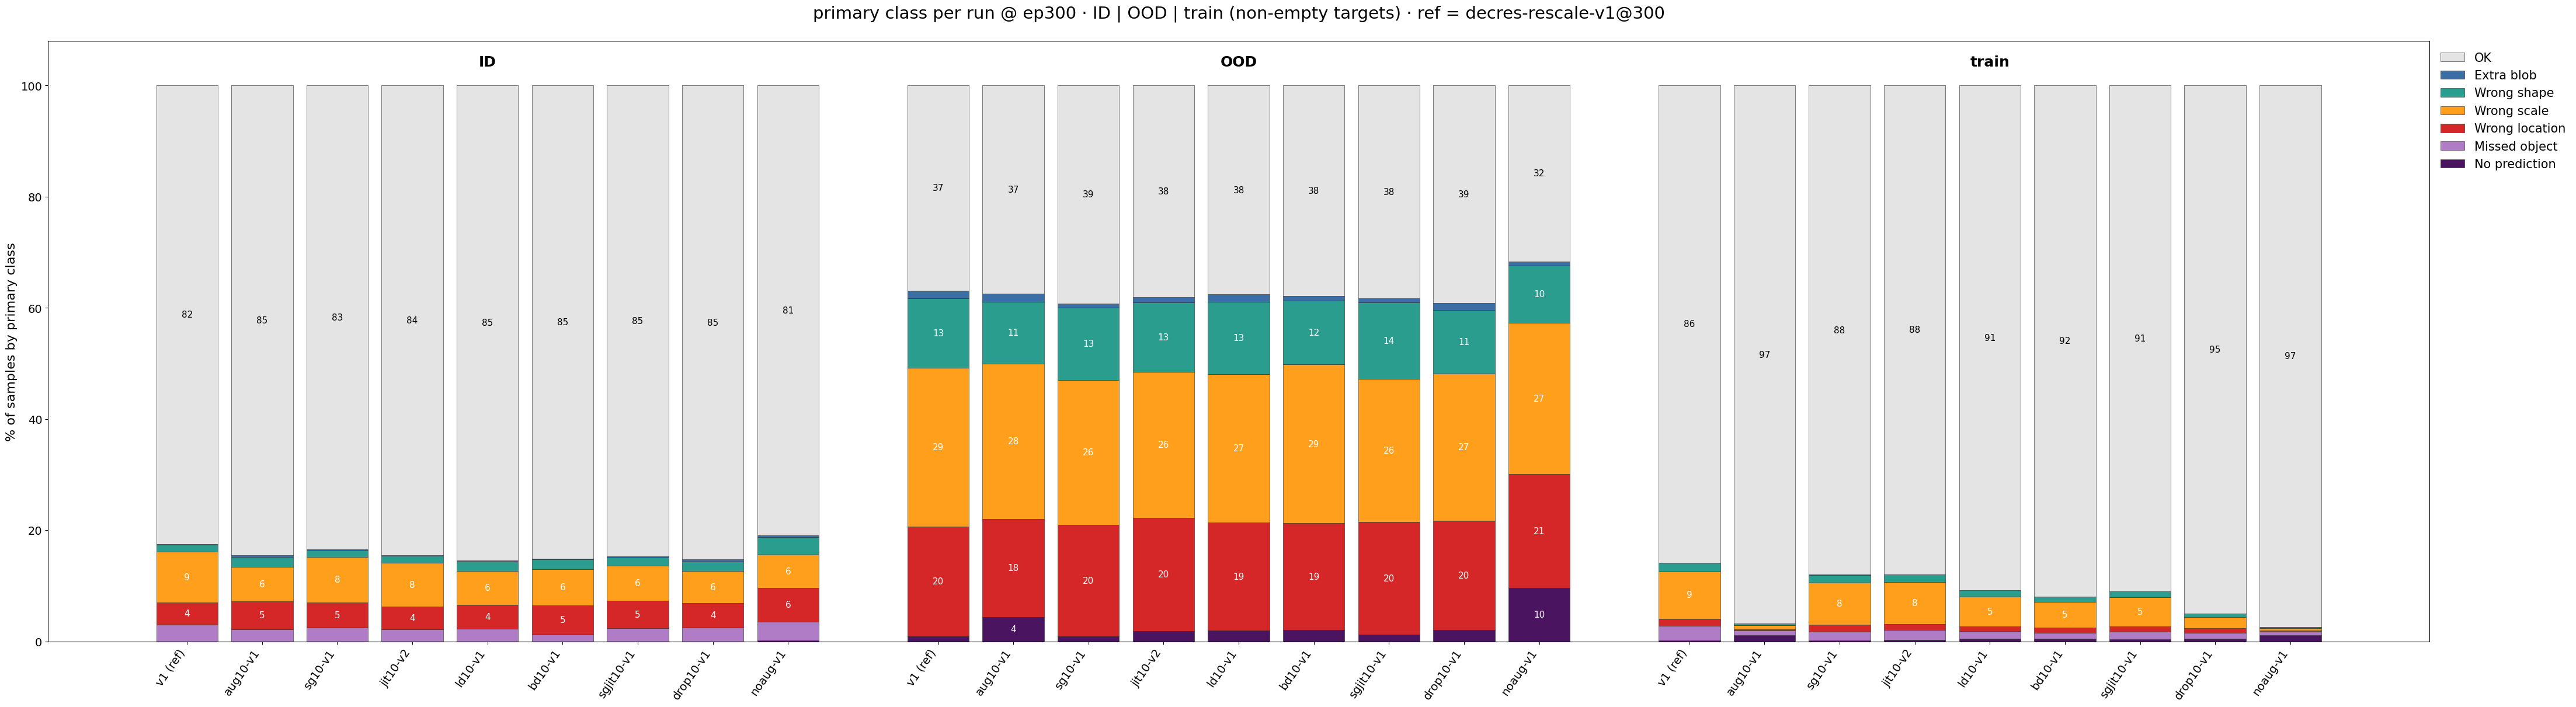

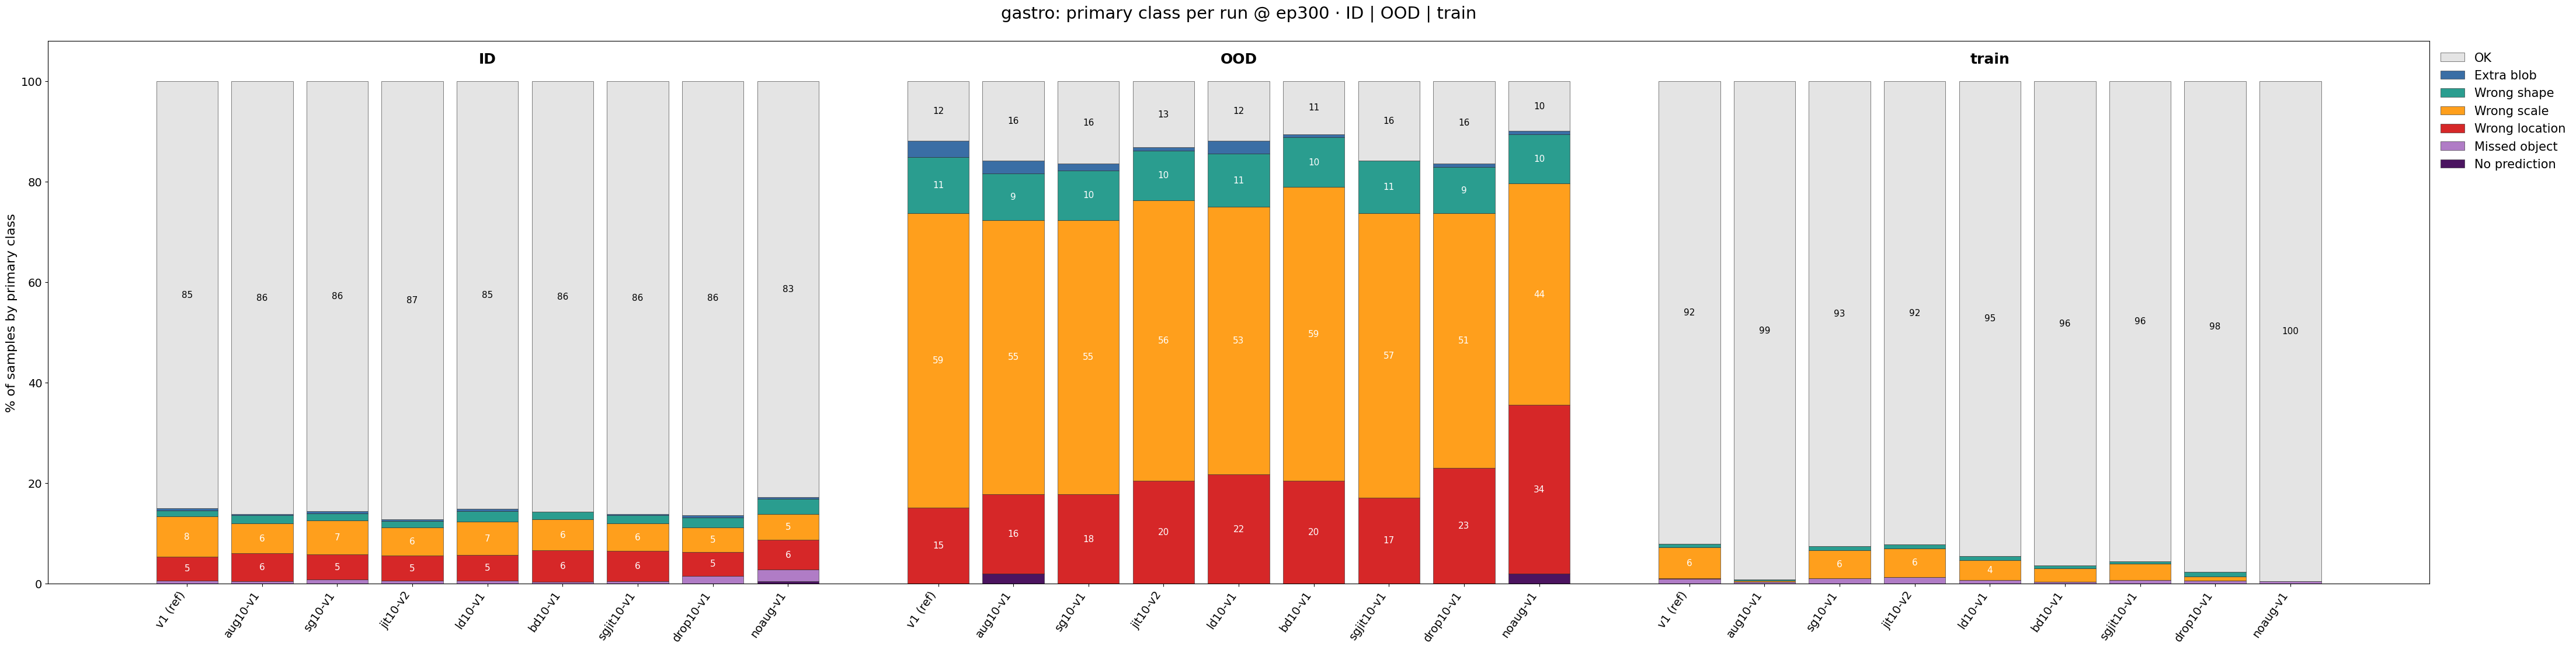

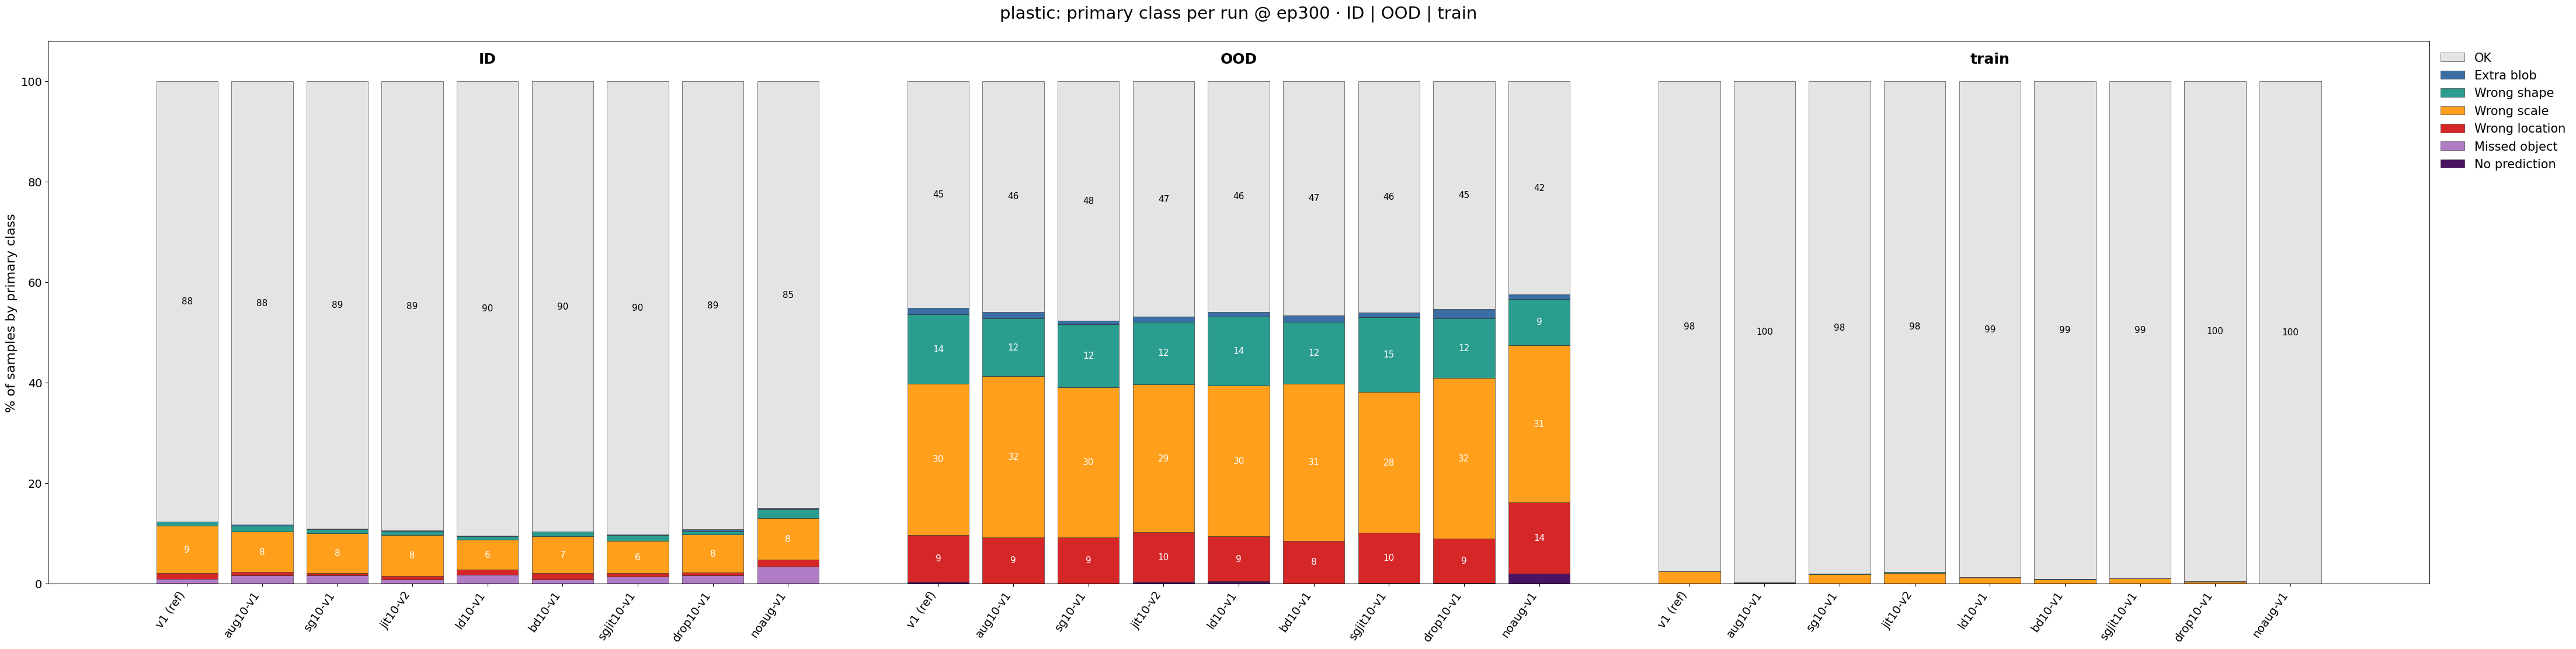

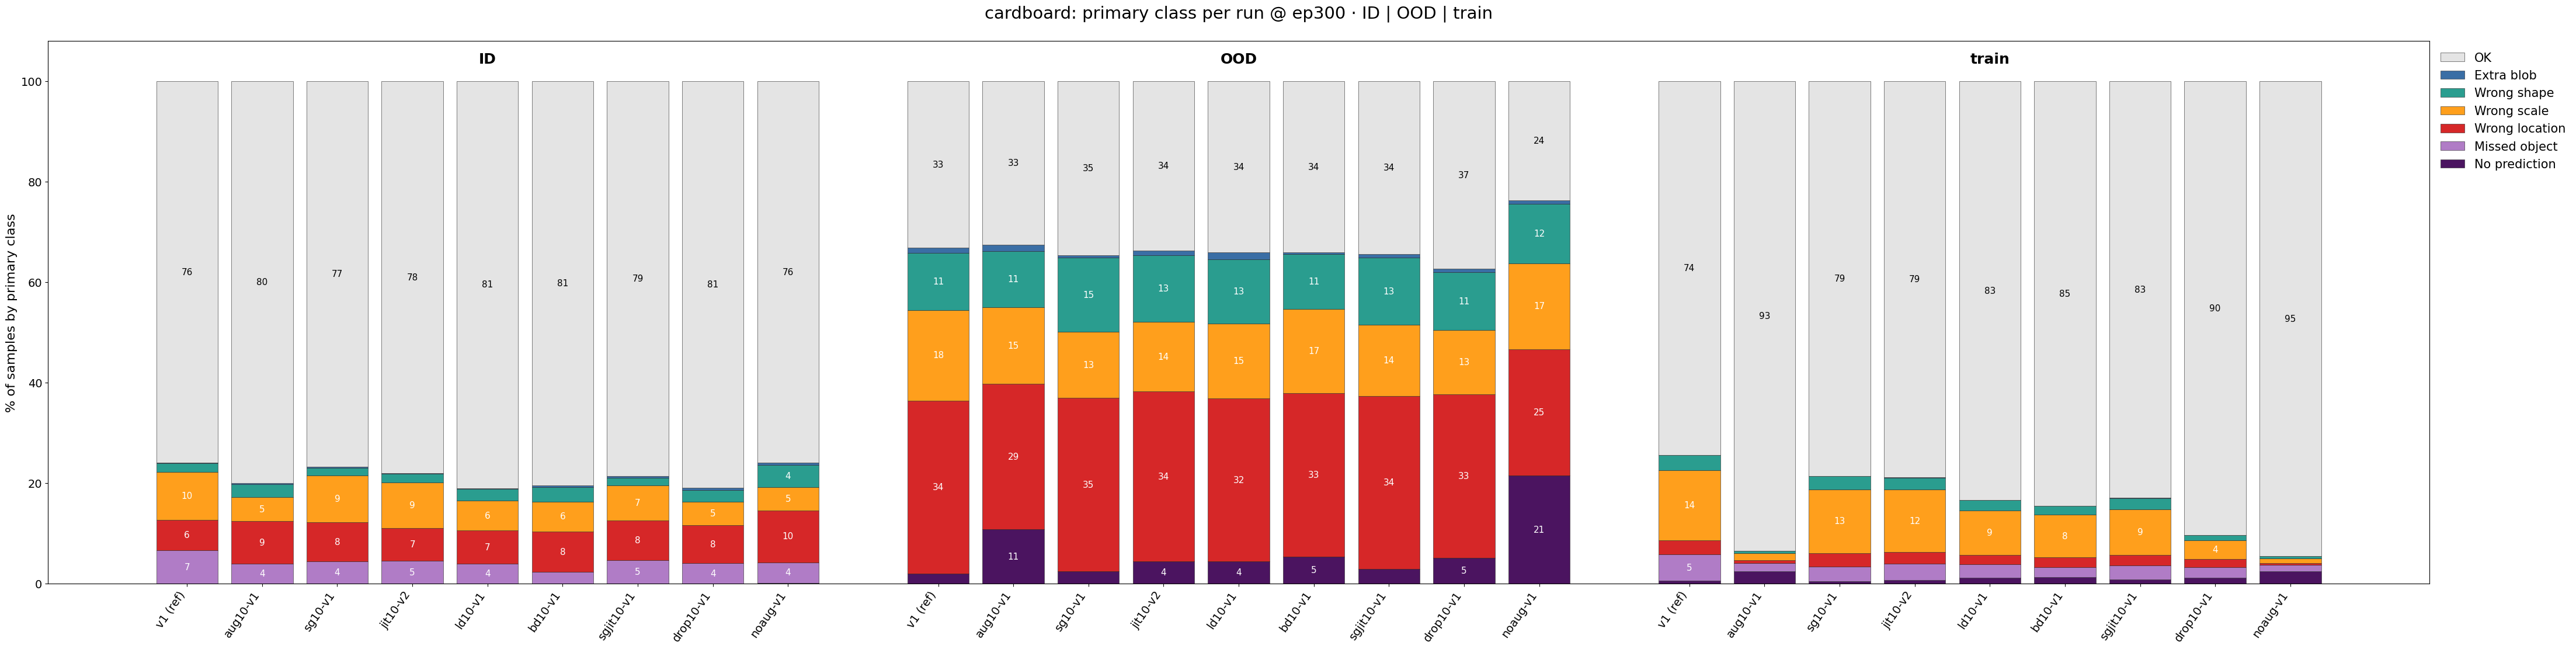

In [6]:
stacked(f"primary class per run @ ep{EP} · ID | OOD | train (non-empty targets) · ref = {LAB[REF]}",
        [(g, [(SH[r], cat(DS[r], cs)) for r in RUNS]) for g, cs in GROUPS], (44, 12))
for b in BOXES:
    stacked(f"{b}: primary class per run @ ep{EP} · ID | OOD | train",
            [(g, [(SH[r], cat(DS[r][DS[r].box == b], cs)) for r in RUNS]) for g, cs in GROUPS], (44, 11))

## B · class rates per run (primary class, % of samples with a non-empty target)

In [7]:
rows = []
for r in RUNS:
    for g, cs in GROUPS:
        s = tgt(cat(DS[r], cs))
        rows.append({"run": LAB[r], "sg / jit / ld / bd": AUG[r], "group": g, "n": len(s), "iou08": s.iou08.mean(), **dict(zip(P7, shares(s)))})
RATES = pd.DataFrame(rows).set_index(["run", "sg / jit / ld / bd", "group"])
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
display(RATES.unstack("group").swaplevel(axis=1)[[(g, c) for g, _ in GROUPS for c in ["n", "iou08"] + P7]].round(3))

group                                               ID                                                                                                OOD                                                                                               \
                                                     n  iou08 No prediction Missed object Wrong location Wrong scale Wrong shape Extra blob      OK     n  iou08 No prediction Missed object Wrong location Wrong scale Wrong shape Extra blob      OK   
run                           sg / jit / ld / bd                                                                                                                                                                                                         
decres-rescale-aug10-v1@300   .1 / .1 / .1 / .1   2501  0.708          0.00         2.199          4.998       6.238       1.799       0.24  84.526  1407  0.382         4.407           0.0         17.626      27.932      11.158      1.421  37.456   
decres-rescale-bd10-v1@300    1 / 1 / 1 / .1      2501  0.708          0.00         1.240          5.238       6.477       1.839       0.12  85.086  1407  0.394         2.061           0.0         19.190      28.571      11.514      0.853  37.811   
decres-rescale-drop10-v1@300  1 / 1 / .1 / .1     2501  0.714          0.00         2.519          4.398       5.718       1.679       0.44  85.246  1407  0.391         2.061           0.0         19.616      26.510      11.443      1.279  39.090   
decres-rescale-jit10-v2@300   1 / .1 / 1 / 1      2501  0.711          0.00         2.199          4.078       7.837       1.279       0.16  84.446  1407  0.392         1.848           0.0         20.398      26.226      12.509      0.924  38.095   
decres-rescale-ld10-v1@300    1 / 1 / .1 / 1      2501  0.717          0.00         2.279          4.278       6.118       1.679       0.24  85.406  1407  0.395         1.919           0.0         19.474      26.652      13.006      1.350  37.598   
decres-rescale-noaug-v1@300   0 / 0 / 0 / 0       2501  0.671          0.16         3.359          6.078       5.998       3.159       0.32  80.928  1407  0.335         9.595           0.0         20.540      27.150      10.306      0.782  31.628   
decres-rescale-sg10-v1@300    .1 / 1 / 1 / 1      2501  0.702          0.00         2.479          4.518       8.157       1.200       0.24  83.407  1407  0.398         0.924           0.0         20.043      26.013      13.077      0.711  39.232   
decres-rescale-sgjit10-v1@300 .1 / .1 / 1 / 1     2501  0.711          0.00         2.399          4.878       6.397       1.439       0.20  84.686  1407  0.393         1.208           0.0         20.256      25.729      13.788      0.782  38.237   
decres-rescale-v1@300         1 / 1 / 1 / 1       2501  0.703          0.00         3.039          3.998       9.076       1.279       0.16  82.447  1407  0.397         0.924           0.0         19.758      28.500      12.509      1.421  36.887   

group                                             train                                                                                               
                                                      n  iou08 No prediction Missed object Wrong location Wrong scale Wrong shape Extra blob      OK  
run                           sg / jit / ld / bd                                                                                                      
decres-rescale-aug10-v1@300   .1 / .1 / .1 / .1   11050  0.890         1.095         0.833          0.235       0.742       0.281      0.000  96.814  
decres-rescale-bd10-v1@300    1 / 1 / 1 / .1      11050  0.832         0.543         0.995          0.923       4.688       0.950      0.009  91.891  
decres-rescale-drop10-v1@300  1 / 1 / .1 / .1     11050  0.865         0.498         1.104          0.742       1.991       0.715      0.000  94.950  
decres-rescale-jit10-v2@300   1 / .1 / 1 / 1      11050  0.806         0.308         1.765   

## C · paired Δ vs decres-rescale-v1 (position bootstrap)
Per sample, Δ = run − decres-rescale-v1 on the same sample: iou08, and each primary class as a 0/100 indicator (pp). "all found" = every true object found (2+-object samples only). The bootstrap resamples (experiment, position_id) clusters N_BOOT times; 95% percentile CI; ★ = CI excludes 0.

ID: run − decres-rescale-v1@300, paired, 95% bootstrap CI over positions (★ = excludes 0)


,sg / jit / ld / bd,pos,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK
run,,,,,,,,,,
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,683,"+0.005 [+0.001,+0.009] ★","+0.0 [+0.0,+0.0]","-0.8 [-1.6,+0.0]","+1.0 [+0.2,+1.9] ★","-2.8 [-4.2,-1.5] ★","+0.5 [-0.1,+1.1]","+0.1 [-0.2,+0.4]","+2.1 [+0.9,+3.2] ★"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,683,"-0.001 [-0.004,+0.002]","+0.0 [+0.0,+0.0]","-0.6 [-1.3,+0.1]","+0.5 [-0.1,+1.2]","-0.9 [-2.0,+0.1]","-0.1 [-0.6,+0.5]","+0.1 [-0.2,+0.4]","+1.0 [+0.2,+1.8] ★"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,683,"+0.008 [+0.005,+0.011] ★","+0.0 [+0.0,+0.0]","-0.8 [-1.4,-0.3] ★","+0.1 [-0.5,+0.7]","-1.2 [-2.3,-0.2] ★","+0.0 [-0.6,+0.6]","+0.0 [-0.2,+0.2]","+2.0 [+1.1,+2.9] ★"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,683,"+0.014 [+0.011,+0.017] ★","+0.0 [+0.0,+0.0]","-0.8 [-1.5,-0.0] ★","+0.3 [-0.4,+1.0]","-3.0 [-4.2,-1.8] ★","+0.4 [-0.2,+1.0]","+0.1 [-0.1,+0.3]","+3.0 [+1.9,+4.1] ★"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,683,"+0.004 [+0.001,+0.008] ★","+0.0 [+0.0,+0.0]","-1.8 [-2.7,-1.0] ★","+1.2 [+0.4,+2.0] ★","-2.6 [-3.7,-1.5] ★","+0.6 [-0.0,+1.2]","-0.0 [-0.2,+0.2]","+2.6 [+1.6,+3.7] ★"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,683,"+0.007 [+0.004,+0.010] ★","+0.0 [+0.0,+0.0]","-0.6 [-1.3,-0.0] ★","+0.9 [+0.2,+1.6] ★","-2.7 [-3.8,-1.5] ★","+0.2 [-0.4,+0.8]","+0.0 [-0.2,+0.3]","+2.2 [+1.1,+3.3] ★"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,683,"+0.010 [+0.007,+0.014] ★","+0.0 [+0.0,+0.0]","-0.5 [-1.4,+0.2]","+0.4 [-0.4,+1.2]","-3.4 [-4.6,-2.2] ★","+0.4 [-0.2,+1.0]","+0.3 [+0.0,+0.6] ★","+2.8 [+1.7,+3.9] ★"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,683,"-0.032 [-0.038,-0.026] ★","+0.2 [+0.0,+0.3] ★","+0.3 [-0.6,+1.4]","+2.1 [+1.2,+3.0] ★","-3.1 [-4.6,-1.6] ★","+1.9 [+1.0,+2.8] ★","+0.2 [-0.1,+0.4]","-1.5 [-2.9,-0.1] ★"


OOD: run − decres-rescale-v1@300, paired, 95% bootstrap CI over positions (★ = excludes 0)


,sg / jit / ld / bd,pos,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK
run,,,,,,,,,,
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,426,"-0.014 [-0.021,-0.008] ★","+3.5 [+2.0,+5.1] ★","+0.0 [+0.0,+0.0]","-2.1 [-4.3,-0.2] ★","-0.6 [-2.9,+1.8]","-1.4 [-3.4,+0.7]","+0.0 [-1.0,+0.8]","+0.6 [-1.8,+2.9]"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,426,"+0.001 [-0.005,+0.007]","+0.0 [-0.5,+0.5]","+0.0 [+0.0,+0.0]","+0.3 [-1.1,+1.8]","-2.5 [-4.4,-0.6] ★","+0.6 [-0.9,+2.1]","-0.7 [-1.5,-0.1] ★","+2.3 [+0.5,+4.2] ★"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,426,"-0.005 [-0.010,-0.000] ★","+0.9 [+0.1,+1.7] ★","+0.0 [+0.0,+0.0]","+0.6 [-0.6,+2.0]","-2.3 [-4.1,-0.5] ★","+0.0 [-1.4,+1.3]","-0.5 [-1.4,+0.4]","+1.2 [-0.6,+3.0]"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,426,"-0.002 [-0.007,+0.004]","+1.0 [+0.3,+1.9] ★","+0.0 [+0.0,+0.0]","-0.3 [-2.0,+1.4]","-1.8 [-3.7,+0.1]","+0.5 [-1.1,+2.2]","-0.1 [-0.8,+0.7]","+0.7 [-1.2,+2.6]"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,426,"-0.003 [-0.009,+0.002]","+1.1 [+0.3,+2.2] ★","+0.0 [+0.0,+0.0]","-0.6 [-2.0,+0.9]","+0.1 [-1.8,+2.0]","-1.0 [-2.5,+0.6]","-0.6 [-1.4,+0.3]","+0.9 [-1.1,+2.8]"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,426,"-0.004 [-0.009,+0.002]","+0.3 [-0.2,+0.9]","+0.0 [+0.0,+0.0]","+0.5 [-0.9,+1.9]","-2.8 [-4.6,-0.9] ★","+1.3 [-0.2,+2.9]","-0.6 [-1.4,+0.1]","+1.4 [-0.6,+3.3]"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,426,"-0.006 [-0.012,+0.000]","+1.1 [+0.4,+2.1] ★","+0.0 [+0.0,+0.0]","-0.1 [-1.9,+1.6]","-2.0 [-4.1,+0.1]","-1.1 [-2.8,+0.6]","-0.1 [-1.0,+0.7]","+2.2 [+0.1,+4.3] ★"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,426,"-0.062 [-0.074,-0.050] ★","+8.7 [+6.5,+10.8] ★","+0.0 [+0.0,+0.0]","+0.8 [-1.9,+3.8]","-1.4 [-4.5,+1.8]","-2.2 [-4.5,-0.1] ★","-0.6 [-1.7,+0.3]","-5.3 [-8.1,-2.4] ★"


train: run − decres-rescale-v1@300, paired, 95% bootstrap CI over positions (★ = excludes 0)


,sg / jit / ld / bd,pos,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK
run,,,,,,,,,,
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,2986,"+0.099 [+0.095,+0.103] ★","+0.9 [+0.6,+1.2] ★","-1.8 [-2.2,-1.4] ★","-1.0 [-1.3,-0.7] ★","-7.8 [-8.6,-7.0] ★","-1.2 [-1.6,-0.9] ★","-0.0 [-0.0,+0.0]","+11.0 [+10.0,+12.0] ★"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,2986,"+0.015 [+0.013,+0.016] ★","-0.0 [-0.1,+0.1]","-1.1 [-1.4,-0.7] ★","-0.0 [-0.2,+0.2]","-0.9 [-1.5,-0.4] ★","-0.1 [-0.3,+0.2]","-0.0 [-0.0,+0.0]","+2.2 [+1.6,+2.6] ★"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,2986,"+0.015 [+0.014,+0.017] ★","+0.1 [-0.1,+0.2]","-0.9 [-1.2,-0.6] ★","-0.2 [-0.4,-0.0] ★","-0.9 [-1.4,-0.4] ★","-0.2 [-0.4,+0.0]","+0.0 [-0.0,+0.0]","+2.1 [+1.6,+2.6] ★"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,2986,"+0.038 [+0.036,+0.040] ★","+0.3 [+0.1,+0.4] ★","-1.2 [-1.6,-0.9] ★","-0.5 [-0.7,-0.2] ★","-3.2 [-3.8,-2.5] ★","-0.4 [-0.7,-0.1] ★","-0.0 [-0.0,+0.0]","+5.0 [+4.3,+5.6] ★"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,2986,"+0.041 [+0.039,+0.043] ★","+0.3 [+0.2,+0.4] ★","-1.6 [-2.0,-1.2] ★","-0.3 [-0.6,-0.1] ★","-3.8 [-4.5,-3.2] ★","-0.6 [-0.9,-0.3] ★","-0.0 [-0.0,+0.0]","+6.0 [+5.4,+6.7] ★"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,2986,"+0.034 [+0.032,+0.036] ★","+0.1 [+0.0,+0.3] ★","-1.2 [-1.5,-0.9] ★","-0.3 [-0.5,-0.1] ★","-3.3 [-3.9,-2.7] ★","-0.4 [-0.7,-0.1] ★","-0.0 [-0.0,+0.0]","+5.1 [+4.5,+5.7] ★"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,2986,"+0.074 [+0.071,+0.077] ★","+0.3 [+0.1,+0.4] ★","-1.5 [-1.9,-1.2] ★","-0.5 [-0.8,-0.3] ★","-6.5 [-7.3,-5.8] ★","-0.8 [-1.1,-0.5] ★","-0.0 [-0.0,+0.0]","+9.1 [+8.2,+10.1] ★"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,2986,"+0.122 [+0.119,+0.127] ★","+0.9 [+0.6,+1.2] ★","-2.0 [-2.4,-1.5] ★","-1.1 [-1.4,-0.8] ★","-8.1 [-9.0,-7.3] ★","-1.3 [-1.7,-0.9] ★","-0.0 [-0.0,+0.0]","+11.6 [+10.6,+12.6] ★"


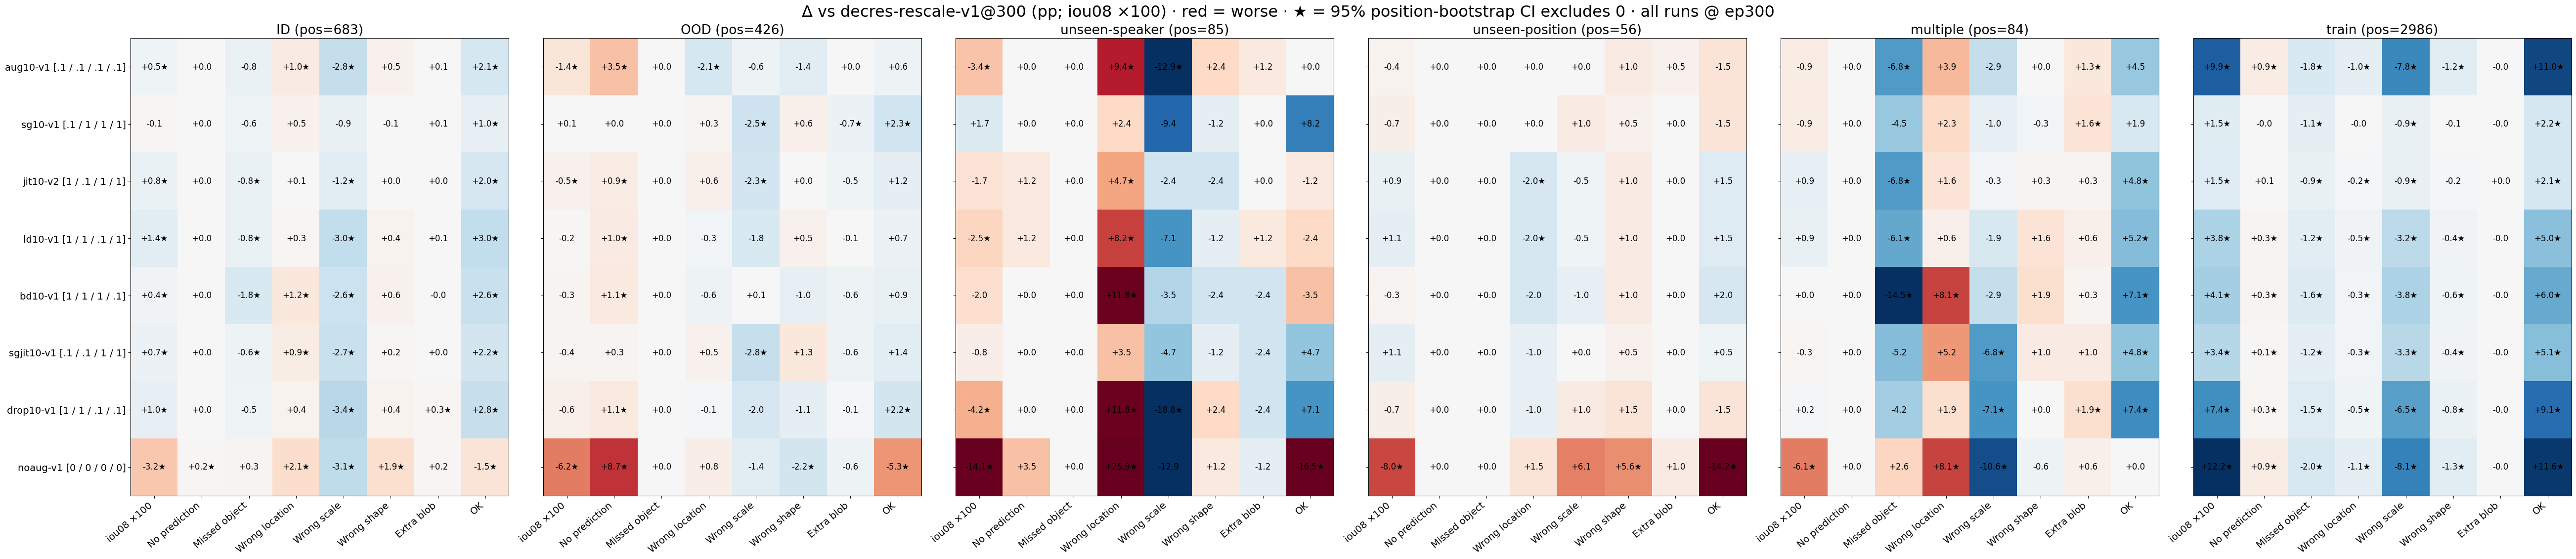

In [8]:
COLS = ["iou08"] + P7 + ["all found"]
def flags(s):
    s = tgt(s); c = p7(s)
    return s[K].assign(iou08=s.iou08, **{n: 100.0 * (c == j) for j, n in enumerate(P7)}, **{"all found": np.where(s.n_obj >= 2, 100.0 * (s.n_missing == 0), np.nan)})

def select(s, spec):
    if spec == "2+": return s[(s.n_obj >= 2) & (s.category != "train")]
    if isinstance(spec, tuple): return cat(s[s.box == spec[0]], spec[1])
    return cat(s, spec)

def eval_groups():
    yield "ID", ID_CATS
    yield "OOD", OOD_CATS
    yield "train", ["train"]
    for b in BOXES:
        for g, cs in (("ID", ID_CATS), ("OOD", OOD_CATS)): yield f"{b} {g}", (b, cs)
    for c in ID_CATS + OOD_CATS + OTHER_CATS: yield f"cat {c}", c
    for b in BOXES: yield f"{b} unseen-speaker", (b, "unseen-speaker")
    yield "2+ objects", "2+"

rng = np.random.default_rng(0)
def boot(a, b, spec):
    m = flags(select(DS[a], spec)).merge(flags(select(DS[b], spec)), on=K, suffixes=("_a", "_b"))
    cl = pd.factorize(pd.Series(list(zip(m.experiment, m.position_id))))[0]; n_cl = cl.max() + 1
    Wt = np.stack([np.bincount(rng.integers(0, n_cl, n_cl), minlength=n_cl) for _ in range(N_BOOT)]).astype(float)
    out = {"n": len(m), "positions": n_cl}
    for c in COLS:
        d = (m[f"{c}_a"] - m[f"{c}_b"]).to_numpy(float); fin = np.isfinite(d)
        if not fin.any(): out[c] = (np.nan, np.nan, np.nan); continue
        S_, N_ = np.bincount(cl[fin], d[fin], n_cl), np.bincount(cl[fin], minlength=n_cl).astype(float)
        out[c] = (d[fin].mean(), *np.percentile((Wt @ S_)[Wt @ N_ > 0] / (Wt @ N_)[Wt @ N_ > 0], [2.5, 97.5]))
    return out

BOOT = {r: {g: boot(r, REF, spec) for g, spec in eval_groups()} for r in RUNS if r != REF}
star = lambda v: v[1] > 0 or v[2] < 0
fmt = lambda c, v: "" if np.isnan(v[0]) else (f"{v[0]:+.3f} [{v[1]:+.3f},{v[2]:+.3f}]" if c == "iou08" else f"{v[0]:+.1f} [{v[1]:+.1f},{v[2]:+.1f}]") + (" ★" if star(v) else "")
for g in ("ID", "OOD", "train"):
    print(f"{g}: run − {LAB[REF]}, paired, 95% bootstrap CI over positions (★ = excludes 0)")
    display(pd.DataFrame([{"run": LAB[r], "sg / jit / ld / bd": AUG[r], "pos": BOOT[r][g]["positions"], **{c: fmt(c, BOOT[r][g][c]) for c in COLS if c != "all found"}} for r in BOOT]).set_index("run"))

# heatmap: rows = runs, columns = class x group, value = Δ, ★ = CI excludes 0
HG = ["ID", "OOD", "cat unseen-speaker", "cat unseen-position", "cat multiple", "train"]
HC = ["iou08", "No prediction", "Missed object", "Wrong location", "Wrong scale", "Wrong shape", "Extra blob", "OK"]
fig, axes = plt.subplots(1, len(HG), figsize=(52, 0.9 * len(BOOT) + 4), sharey=True, constrained_layout=True)
for ax, g in zip(axes, HG):
    M = np.array([[BOOT[r][g][c][0] * (100 if c == "iou08" else 1) for c in HC] for r in BOOT])
    sgn = np.array([-1 if c in ("iou08", "OK") else 1 for c in HC])            # red = worse than the reference
    ax.imshow(M * sgn, cmap="RdBu_r", vmin=-12, vmax=12, aspect="auto")
    for i, r in enumerate(BOOT):
        for j, c in enumerate(HC):
            v = BOOT[r][g][c]
            if np.isfinite(v[0]): ax.text(j, i, (f"{100 * v[0]:+.1f}" if c == "iou08" else f"{v[0]:+.1f}") + ("★" if star(v) else ""), ha="center", va="center", fontsize=12)
    ax.set_xticks(range(len(HC)), [c if c != "iou08" else "iou08 ×100" for c in HC], rotation=40, ha="right")
    ax.set_title(f"{g.replace('cat ', '')} (pos={BOOT[next(iter(BOOT))][g]['positions']})", fontsize=19)
axes[0].set_yticks(range(len(BOOT)), [f"{SH[r]} [{AUG[r]}]" for r in BOOT])
fig.suptitle(f"Δ vs {LAB[REF]} (pp; iou08 ×100) · red = worse · ★ = 95% position-bootstrap CI excludes 0 · all runs @ ep{EP}", fontsize=23)
plt.show()

## D · where the losses go: unseen-speaker, unseen-position, multiple
Does noaug's OOD collapse show up as No prediction, or as wrong location / scale? Which class rises when each aug is reduced or removed? Each group below is broken down by primary class per run, per box for unseen-speaker. For the 2+-object samples it also gives "all objects found" %.

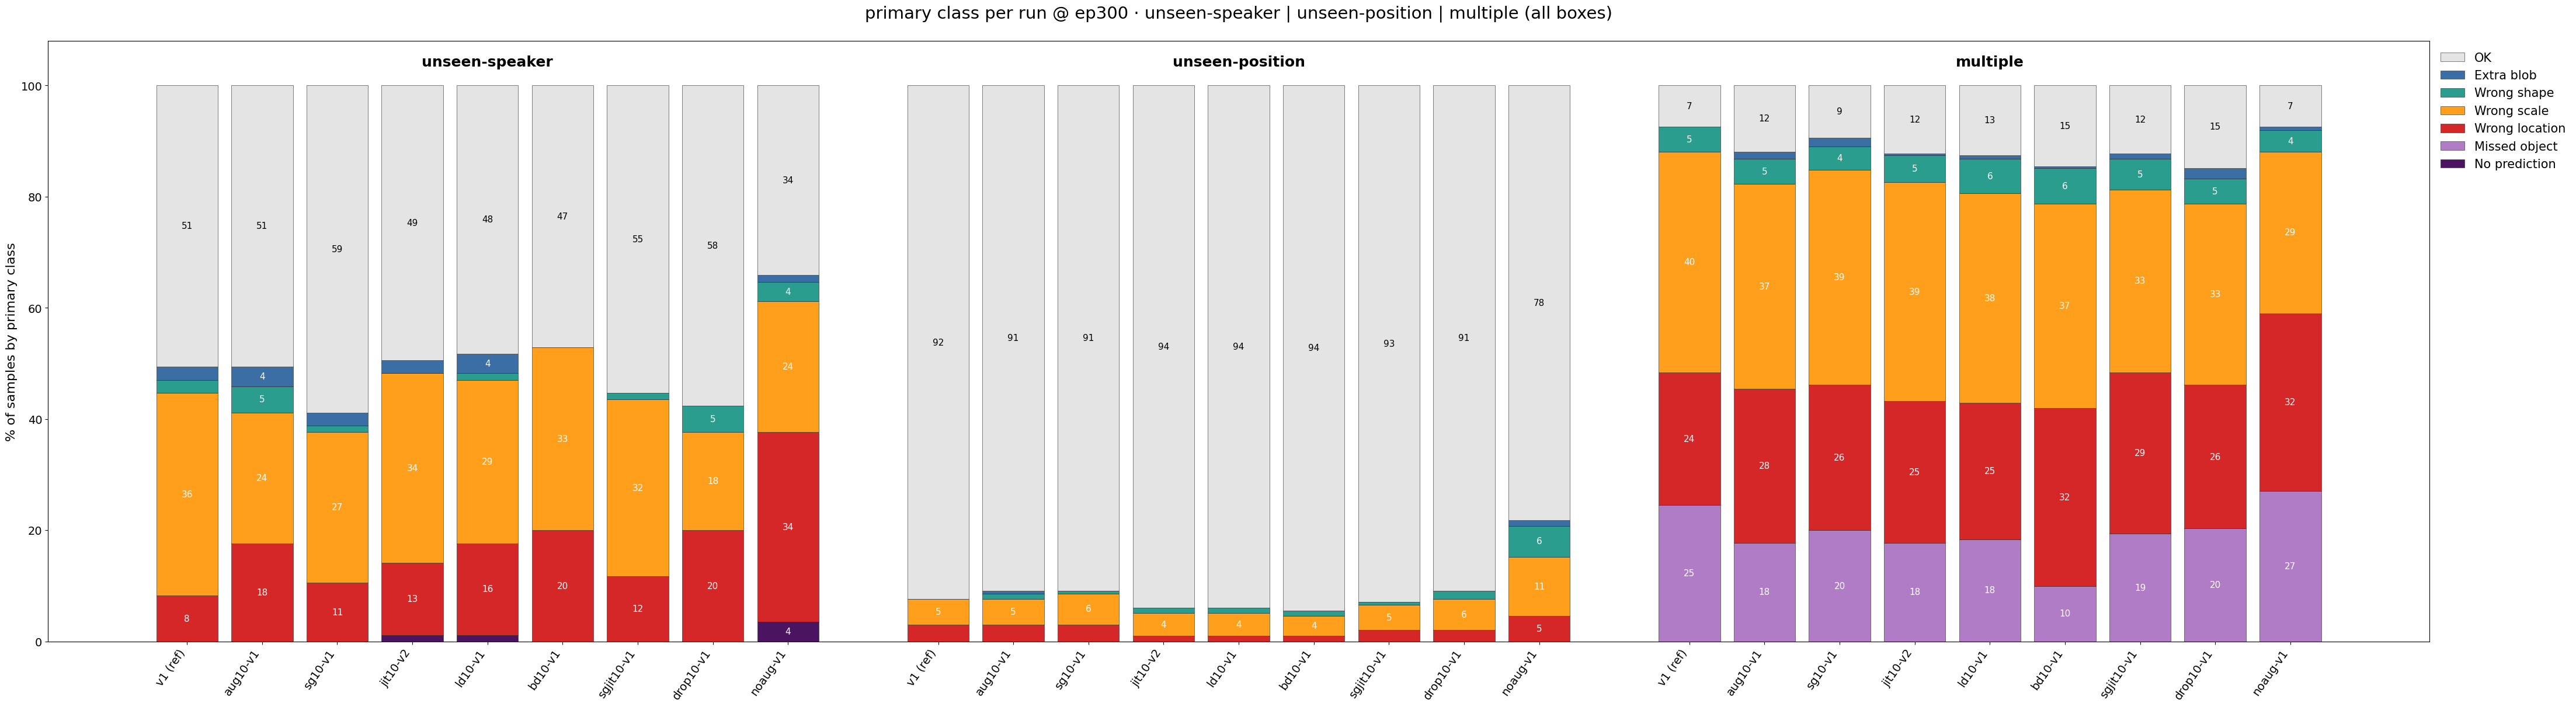

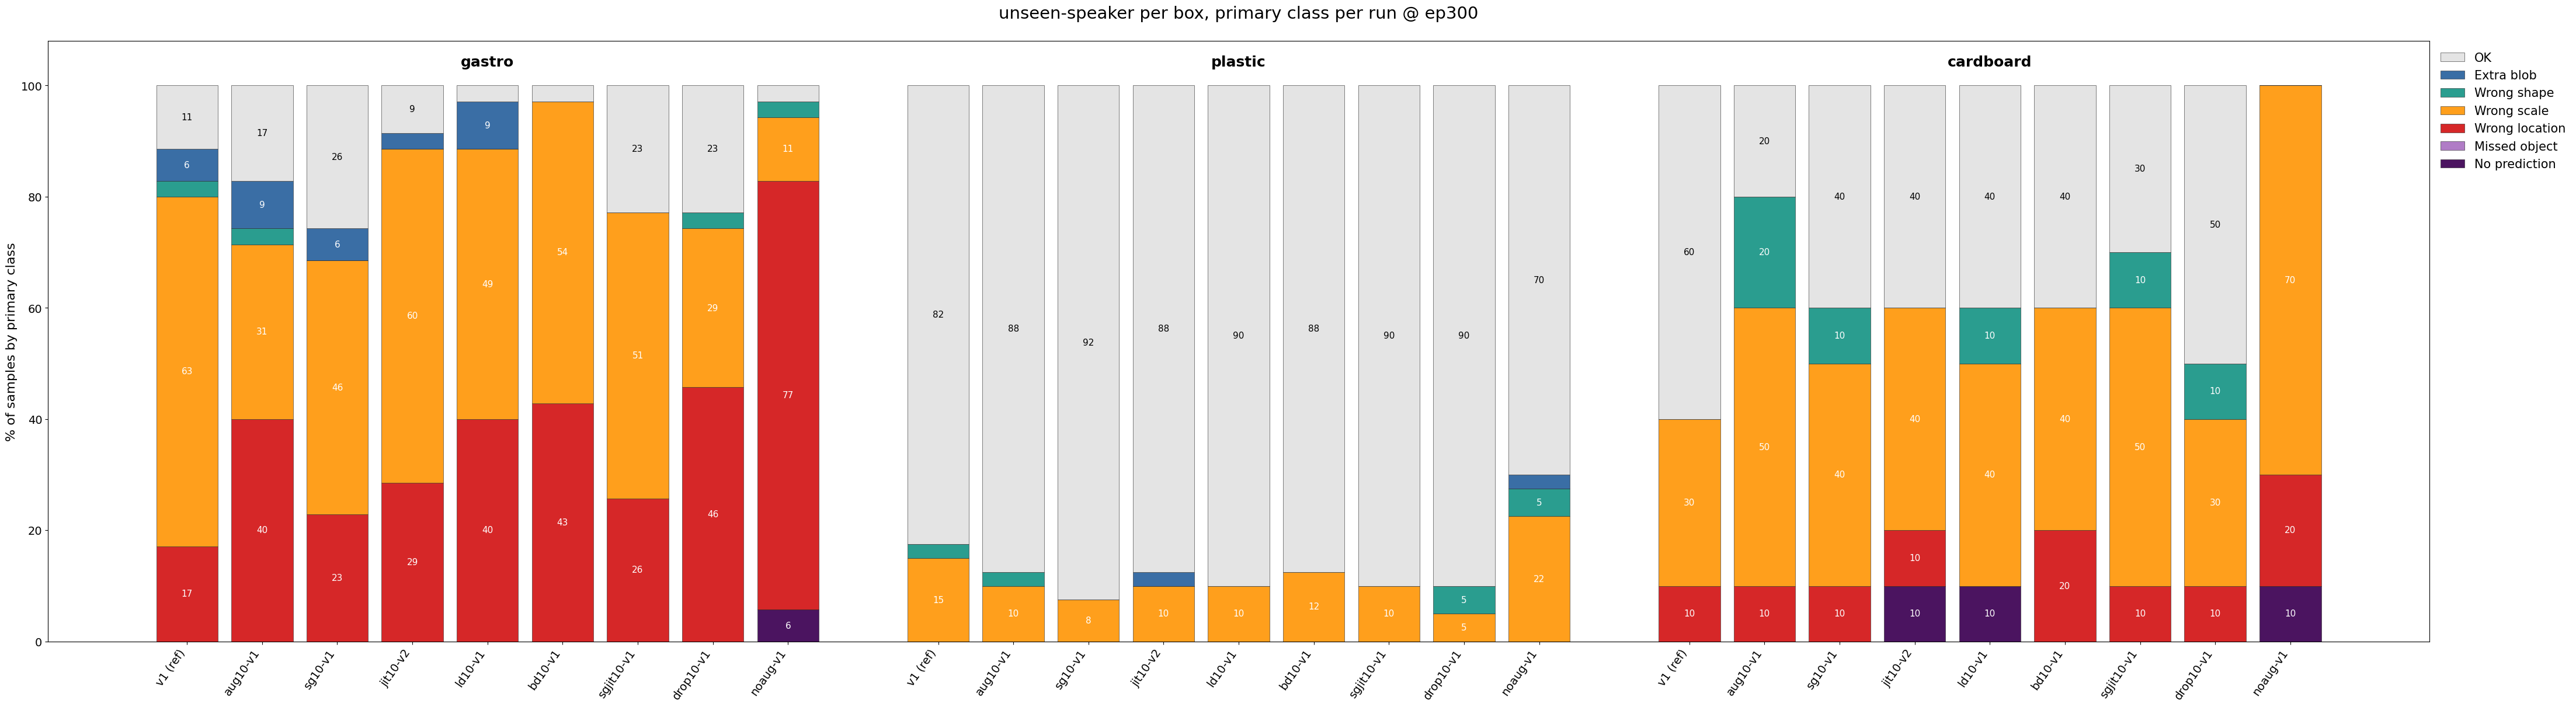

cardboard unseen-speaker


,sg / jit / ld / bd,n,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK,Δ iou08,Δ No prediction,Δ Wrong location,Δ Wrong scale,Δ OK
run,,,,,,,,,,,,,,,
decres-rescale-v1@300,1 / 1 / 1 / 1,10,0.47,0.0,0.0,10.0,30.0,0.0,0.0,60.0,NaN,NaN,NaN,NaN,NaN
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,10,0.41,0.0,0.0,10.0,50.0,20.0,0.0,20.0,"-0.054 [-0.156,+0.044]","+0.0 [+0.0,+0.0]","+0.0 [-30.0,+30.0]","+20.0 [-20.0,+60.0]","-40.0 [-70.0,-10.0] ★"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,10,0.46,0.0,0.0,10.0,40.0,10.0,0.0,40.0,"-0.013 [-0.103,+0.067]","+0.0 [+0.0,+0.0]","+0.0 [-30.0,+30.0]","+10.0 [-20.0,+40.0]","-20.0 [-50.0,+0.0]"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,10,0.43,10.0,0.0,10.0,40.0,0.0,0.0,40.0,"-0.037 [-0.142,+0.042]","+10.0 [+0.0,+30.0]","+0.0 [+0.0,+0.0]","+10.0 [-30.0,+50.0]","-20.0 [-50.0,+20.0]"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,10,0.39,10.0,0.0,0.0,40.0,10.0,0.0,40.0,"-0.076 [-0.175,+0.005]","+10.0 [+0.0,+30.0]","-10.0 [-30.0,+0.0]","+10.0 [-20.0,+40.0]","-20.0 [-60.0,+20.0]"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,10,0.43,0.0,0.0,20.0,40.0,0.0,0.0,40.0,"-0.040 [-0.146,+0.051]","+0.0 [+0.0,+0.0]","+10.0 [+0.0,+30.0]","+10.0 [-20.0,+40.0]","-20.0 [-50.0,+0.0]"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,10,0.41,0.0,0.0,10.0,50.0,10.0,0.0,30.0,"-0.063 [-0.131,+0.003]","+0.0 [+0.0,+0.0]","+0.0 [+0.0,+0.0]","+20.0 [+0.0,+50.0]","-30.0 [-60.0,+0.0]"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,10,0.39,0.0,0.0,10.0,30.0,10.0,0.0,50.0,"-0.077 [-0.168,-0.007] ★","+0.0 [+0.0,+0.0]","+0.0 [-30.0,+30.0]","+0.0 [-30.0,+30.0]","-10.0 [-30.0,+0.0]"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,10,0.24,10.0,0.0,20.0,70.0,0.0,0.0,0.0,"-0.228 [-0.341,-0.101] ★","+10.0 [+0.0,+30.0]","+10.0 [-20.0,+40.0]","+40.0 [-20.0,+80.0]","-60.0 [-90.0,-30.0] ★"


gastro unseen-speaker


,sg / jit / ld / bd,n,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK,Δ iou08,Δ No prediction,Δ Wrong location,Δ Wrong scale,Δ OK
run,,,,,,,,,,,,,,,
decres-rescale-v1@300,1 / 1 / 1 / 1,35,0.30,0.00,0.0,17.14,62.86,2.86,5.71,11.43,NaN,NaN,NaN,NaN,NaN
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,35,0.19,0.00,0.0,40.00,31.43,2.86,8.57,17.14,"-0.112 [-0.159,-0.067] ★","+0.0 [+0.0,+0.0]","+22.9 [+8.6,+40.0] ★","-31.4 [-51.4,-11.4] ★","+5.7 [-8.6,+20.0]"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,35,0.27,0.00,0.0,22.86,45.71,0.00,5.71,25.71,"-0.034 [-0.067,-0.001] ★","+0.0 [+0.0,+0.0]","+5.7 [+0.0,+14.3]","-17.1 [-31.4,-2.9] ★","+14.3 [+0.0,+28.6]"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,35,0.27,0.00,0.0,28.57,60.00,0.00,2.86,8.57,"-0.029 [-0.057,-0.004] ★","+0.0 [+0.0,+0.0]","+11.4 [+2.9,+22.9] ★","-2.9 [-14.3,+8.6]","-2.9 [-8.6,+0.0]"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,35,0.22,0.00,0.0,40.00,48.57,0.00,8.57,2.86,"-0.083 [-0.119,-0.050] ★","+0.0 [+0.0,+0.0]","+22.9 [+8.6,+37.1] ★","-14.3 [-31.4,+2.9]","-8.6 [-20.0,+0.0]"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,35,0.21,0.00,0.0,42.86,54.29,0.00,0.00,2.86,"-0.090 [-0.140,-0.045] ★","+0.0 [+0.0,+0.0]","+25.7 [+8.6,+42.9] ★","-8.6 [-25.7,+8.6]","-8.6 [-20.0,+0.0]"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,35,0.26,0.00,0.0,25.71,51.43,0.00,0.00,22.86,"-0.038 [-0.076,+0.001]","+0.0 [+0.0,+0.0]","+8.6 [-5.7,+22.9]","-11.4 [-28.6,+8.6]","+11.4 [+0.0,+25.7]"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,35,0.19,0.00,0.0,45.71,28.57,2.86,0.00,22.86,"-0.107 [-0.158,-0.057] ★","+0.0 [+0.0,+0.0]","+28.6 [+14.3,+42.9] ★","-34.3 [-51.4,-14.3] ★","+11.4 [-5.7,+28.6]"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,35,0.04,5.71,0.0,77.14,11.43,2.86,0.00,2.86,"-0.255 [-0.317,-0.198] ★","+5.7 [+0.0,+14.3]","+60.0 [+42.9,+77.1] ★","-51.4 [-68.6,-34.3] ★","-8.6 [-20.0,+2.9]"


multiple


,sg / jit / ld / bd,n,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK,all found %,Δ iou08,Δ No prediction,Δ Wrong location,Δ Wrong scale,Δ OK,Δ all found
run,,,,,,,,,,,,,,,,,
decres-rescale-v1@300,1 / 1 / 1 / 1,310,0.39,0.0,24.52,23.87,39.68,4.52,0.00,7.42,75.48,NaN,NaN,NaN,NaN,NaN,NaN
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,310,0.38,0.0,17.74,27.74,36.77,4.52,1.29,11.94,82.26,"-0.009 [-0.021,+0.004]","+0.0 [+0.0,+0.0]","+3.9 [-2.6,+10.1]","-2.9 [-10.3,+4.4]","+4.5 [-0.6,+9.7]","+6.8 [+0.6,+12.8] ★"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,310,0.38,0.0,20.00,26.13,38.71,4.19,1.61,9.35,80.00,"-0.009 [-0.019,+0.001]","+0.0 [+0.0,+0.0]","+2.3 [-2.0,+7.0]","-1.0 [-7.8,+6.0]","+1.9 [-1.9,+5.4]","+4.5 [-1.0,+10.4]"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,310,0.40,0.0,17.74,25.48,39.35,4.84,0.32,12.26,82.26,"+0.009 [-0.001,+0.021]","+0.0 [+0.0,+0.0]","+1.6 [-2.9,+6.1]","-0.3 [-6.8,+6.5]","+4.8 [+0.3,+9.3] ★","+6.8 [+2.8,+11.3] ★"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,310,0.40,0.0,18.39,24.52,37.74,6.13,0.65,12.58,81.61,"+0.009 [-0.001,+0.019]","+0.0 [+0.0,+0.0]","+0.6 [-4.5,+5.6]","-1.9 [-8.1,+3.9]","+5.2 [+1.0,+9.3] ★","+6.1 [+0.3,+12.5] ★"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,310,0.39,0.0,10.00,31.94,36.77,6.45,0.32,14.52,90.00,"+0.000 [-0.009,+0.011]","+0.0 [+0.0,+0.0]","+8.1 [+2.6,+13.8] ★","-2.9 [-8.8,+2.9]","+7.1 [+2.5,+11.7] ★","+14.5 [+8.7,+21.0] ★"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,310,0.39,0.0,19.35,29.03,32.90,5.48,0.97,12.26,80.65,"-0.003 [-0.013,+0.008]","+0.0 [+0.0,+0.0]","+5.2 [-0.0,+10.7]","-6.8 [-13.1,-0.6] ★","+4.8 [+1.0,+8.9] ★","+5.2 [+0.0,+10.4]"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,310,0.39,0.0,20.32,25.81,32.58,4.52,1.94,14.84,79.68,"+0.002 [-0.010,+0.013]","+0.0 [+0.0,+0.0]","+1.9 [-3.3,+7.6]","-7.1 [-13.5,-0.6] ★","+7.4 [+3.0,+11.9] ★","+4.2 [-2.3,+10.6]"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,310,0.33,0.0,27.10,31.94,29.03,3.87,0.65,7.42,72.90,"-0.061 [-0.081,-0.041] ★","+0.0 [+0.0,+0.0]","+8.1 [+1.9,+14.4] ★","-10.6 [-18.6,-2.0] ★","+0.0 [-5.2,+4.9]","-2.6 [-10.3,+5.2]"


... (2 outputs left out)

unseen-position


,sg / jit / ld / bd,n,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK,Δ iou08,Δ No prediction,Δ Wrong location,Δ Wrong scale,Δ OK
run,,,,,,,,,,,,,,,
decres-rescale-v1@300,1 / 1 / 1 / 1,197,0.69,0.0,0.0,3.05,4.57,0.00,0.00,92.39,NaN,NaN,NaN,NaN,NaN
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,197,0.69,0.0,0.0,3.05,4.57,1.02,0.51,90.86,"-0.004 [-0.019,+0.012]","+0.0 [+0.0,+0.0]","+0.0 [-2.5,+2.5]","+0.0 [-3.6,+3.5]","-1.5 [-6.5,+3.6]"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,197,0.68,0.0,0.0,3.05,5.58,0.51,0.00,90.86,"-0.007 [-0.019,+0.006]","+0.0 [+0.0,+0.0]","+0.0 [-3.0,+3.5]","+1.0 [-3.0,+5.6]","-1.5 [-7.0,+3.6]"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,197,0.70,0.0,0.0,1.02,4.06,1.02,0.00,93.91,"+0.009 [-0.002,+0.019]","+0.0 [+0.0,+0.0]","-2.0 [-4.1,-0.5] ★","-0.5 [-3.7,+3.0]","+1.5 [-2.5,+5.1]"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,197,0.70,0.0,0.0,1.02,4.06,1.02,0.00,93.91,"+0.011 [-0.001,+0.023]","+0.0 [+0.0,+0.0]","-2.0 [-4.1,-0.5] ★","-0.5 [-4.7,+4.0]","+1.5 [-3.7,+6.2]"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,197,0.69,0.0,0.0,1.02,3.55,1.02,0.00,94.42,"-0.003 [-0.015,+0.008]","+0.0 [+0.0,+0.0]","-2.0 [-5.1,+0.5]","-1.0 [-3.1,+1.0]","+2.0 [-1.0,+5.2]"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,197,0.70,0.0,0.0,2.03,4.57,0.51,0.00,92.89,"+0.011 [-0.001,+0.025]","+0.0 [+0.0,+0.0]","-1.0 [-3.6,+1.5]","+0.0 [-3.1,+3.5]","+0.5 [-3.6,+4.5]"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,197,0.68,0.0,0.0,2.03,5.58,1.52,0.00,90.86,"-0.007 [-0.021,+0.007]","+0.0 [+0.0,+0.0]","-1.0 [-3.1,+1.0]","+1.0 [-2.5,+4.5]","-1.5 [-5.5,+2.6]"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,197,0.61,0.0,0.0,4.57,10.66,5.58,1.02,78.17,"-0.080 [-0.104,-0.059] ★","+0.0 [+0.0,+0.0]","+1.5 [-0.5,+3.6]","+6.1 [+0.0,+13.0]","-14.2 [-23.1,-6.1] ★"


unseen-speaker


,sg / jit / ld / bd,n,iou08,No prediction,Missed object,Wrong location,Wrong scale,Wrong shape,Extra blob,OK,Δ iou08,Δ No prediction,Δ Wrong location,Δ Wrong scale,Δ OK
run,,,,,,,,,,,,,,,
decres-rescale-v1@300,1 / 1 / 1 / 1,85,0.47,0.00,0.0,8.24,36.47,2.35,2.35,50.59,NaN,NaN,NaN,NaN,NaN
decres-rescale-aug10-v1@300,.1 / .1 / .1 / .1,85,0.43,0.00,0.0,17.65,23.53,4.71,3.53,50.59,"-0.034 [-0.065,-0.005] ★","+0.0 [+0.0,+0.0]","+9.4 [+2.4,+17.6] ★","-12.9 [-24.7,-2.4] ★","+0.0 [-9.4,+9.4]"
decres-rescale-sg10-v1@300,.1 / 1 / 1 / 1,85,0.48,0.00,0.0,10.59,27.06,1.18,2.35,58.82,"+0.017 [-0.007,+0.041]","+0.0 [+0.0,+0.0]","+2.4 [-2.4,+7.1]","-9.4 [-18.8,+0.0]","+8.2 [+0.0,+17.6]"
decres-rescale-jit10-v2@300,1 / .1 / 1 / 1,85,0.45,1.18,0.0,12.94,34.12,0.00,2.35,49.41,"-0.017 [-0.037,+0.002]","+1.2 [+0.0,+3.5]","+4.7 [+1.2,+9.4] ★","-2.4 [-10.6,+5.9]","-1.2 [-8.2,+5.9]"
decres-rescale-ld10-v1@300,1 / 1 / .1 / 1,85,0.44,1.18,0.0,16.47,29.41,1.18,3.53,48.24,"-0.025 [-0.053,-0.000] ★","+1.2 [+0.0,+3.5]","+8.2 [+2.3,+15.3] ★","-7.1 [-16.5,+1.2]","-2.4 [-10.6,+4.7]"
decres-rescale-bd10-v1@300,1 / 1 / 1 / .1,85,0.45,0.00,0.0,20.00,32.94,0.00,0.00,47.06,"-0.020 [-0.050,+0.009]","+0.0 [+0.0,+0.0]","+11.8 [+4.7,+20.0] ★","-3.5 [-14.1,+7.1]","-3.5 [-11.8,+3.5]"
decres-rescale-sgjit10-v1@300,.1 / .1 / 1 / 1,85,0.46,0.00,0.0,11.76,31.76,1.18,0.00,55.29,"-0.008 [-0.033,+0.016]","+0.0 [+0.0,+0.0]","+3.5 [-2.4,+9.4]","-4.7 [-14.1,+4.7]","+4.7 [-3.5,+12.9]"
decres-rescale-drop10-v1@300,1 / 1 / .1 / .1,85,0.42,0.00,0.0,20.00,17.65,4.71,0.00,57.65,"-0.042 [-0.073,-0.012] ★","+0.0 [+0.0,+0.0]","+11.8 [+4.7,+20.0] ★","-18.8 [-29.4,-9.4] ★","+7.1 [-1.2,+16.5]"
decres-rescale-noaug-v1@300,0 / 0 / 0 / 0,85,0.32,3.53,0.0,34.12,23.53,3.53,1.18,34.12,"-0.141 [-0.184,-0.098] ★","+3.5 [+0.0,+8.2]","+25.9 [+15.3,+36.5] ★","-12.9 [-28.2,+1.2]","-16.5 [-28.2,-4.7] ★"


In [9]:
SPEC = [("unseen-speaker", "unseen-speaker"), ("unseen-position", "unseen-position"), ("multiple", "multiple")]
stacked(f"primary class per run @ ep{EP} · unseen-speaker | unseen-position | multiple (all boxes)",
        [(g, [(SH[r], cat(DS[r], cs)) for r in RUNS]) for g, cs in SPEC], (44, 12))
stacked(f"unseen-speaker per box, primary class per run @ ep{EP}",
        [(b, [(SH[r], cat(DS[r][DS[r].box == b], "unseen-speaker")) for r in RUNS]) for b in BOXES], (44, 12))

rows = []
for r in RUNS:
    for g, spec in [("unseen-speaker", "cat unseen-speaker")] + [(f"{b} unseen-speaker", f"{b} unseen-speaker") for b in BOXES] + [("unseen-position", "cat unseen-position"), ("multiple", "cat multiple")]:
        s = tgt(select(DS[r], spec[4:] if spec.startswith("cat ") else (spec.split()[0], "unseen-speaker")))
        bt = BOOT.get(r, {}).get(spec)
        row = {"run": LAB[r], "sg / jit / ld / bd": AUG[r], "group": g, "n": len(s), "iou08": s.iou08.mean(), **dict(zip(P7, shares(s)))}
        if g == "multiple": row["all found %"] = 100 * (s.n_missing == 0).mean()
        if bt: row |= {f"Δ {c}": fmt(c, bt[c]) for c in ("iou08", "No prediction", "Wrong location", "Wrong scale", "OK") + (("all found",) if g == "multiple" else ())}
        rows.append(row)
BREAK = pd.DataFrame(rows).set_index(["group", "run"]).sort_index(level=0, sort_remaining=False)
for g in BREAK.index.get_level_values(0).unique():
    print(g); display(BREAK.loc[g].dropna(axis=1, how="all").round(2))

## Verdict
Primary class, % of samples. Δ vs decres-rescale-v1@300, paired, 95% position-bootstrap CI; ★ = CI excludes 0. Nine runs; the only-* isolation runs are not saved yet.

**1. noaug's OOD collapse is mostly No prediction, and on unseen-speaker it is Wrong location.**
- OOD: No prediction 0.9 → 9.6% (+8.7★) and OK 36.9 → 31.6% (−5.3★). Location (+0.8) and scale (−1.4) are not significant.
- Unseen-speaker is the exception: Wrong location 8 → 34% (+25.9★), OK −16.5★. In gastro unseen-speaker 77% of samples are Wrong location (vs 17%), so the model paints a confident blob in the wrong place.
- Unseen-position: OK 92 → 78% (−14.2★), spread over scale (+6.1) and shape (+5.6★).
- ID: OK −1.5★, location +2.1★, shape +1.9★.
- Train: OK 86 → 97% and iou08 +.122★. It overfits.

**2. All four at 10% (aug10) brings No prediction back partly:** OOD +3.5★ (4.4%), iou08 −.014★. It moves gastro unseen-speaker from scale to location (+22.9★ location, −31.4★ scale).

**3. Each single reduction, with the other augs at 100%:**
- ID gets slightly better (OK +1.0 to +3.0★, mostly fewer Wrong scale, −1 to −3★).
- OOD No prediction rises by about +1 pp★ for jit10, ld10, bd10 and drop10, but not for sg10 (+0.0).
- Unseen-speaker Wrong location rises when dropout or jitter is reduced: ld10 +8.2★, bd10 +11.8★, drop10 +11.8★, jit10 +4.7★. sg10 gives only +2.4 (n.s.), and sg10 is in fact the best unseen-speaker run (OK +8.2, iou08 +.017).
- So less speaker gain does not show up as more misses on unseen-speaker. Lower dropout shows up as misplaced blobs there, and in gastro (35 samples) that is +23 to +29 pp★.

**4. Multi-object: full dropout drops the second object.**
- All objects found: 75.5% for the reference vs 80–90% for every reduced run (bd10 90.0%, +14.5★; jit10 +6.8★; ld10 +6.1★; aug10 +6.8★).
- noaug is 72.9% (−2.6, n.s.), but it has more Wrong location (+8.1★) and less Wrong scale (−10.6★).

**5. Not yet separable:** which aug drives which split. Every reduced run keeps the other augs at 100%; the only-* isolation runs will answer this, and this notebook picks them up on re-run.